Week 8 notebook, k nearest neighbors and distance metrics, Mike Hembree

Same project as the earlier weeks. The capstone is an early warning model for ICU delirium on MIMIC IV, and the MIMIC part of this notebook runs on the MIMIC IV Clinical Database Demo (100 patients, 140 ICU stays) because the full credentialed access is still pending. The second dataset is the ECAMS EEG data from Massachusetts General Hospital (373 patients, 1189 EEG features, delirium called by the CAM algorithm), the same two datasets as the Milestone One notebooks. This week is classification on both, a positive delirium screen for MIMIC (45 of 140 stays) and a delirious call for ECAMS (254 of 373 patients). Validation is repeated stratified five fold cross validation with three repeats, and imputation, scaling and any tuning happen inside each training fold. The MIMIC feature table is the same one from the Week 2 notebook and the first code cell saves it so the later weeks can load it.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, accuracy_score

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'

In [2]:
# build the mimic feature table from the raw demo tables, same item ids as the Week 2 notebook
icu = pd.read_csv('mimic-iv-clinical-database-demo-2.2/icu/icustays.csv.gz')
pts = pd.read_csv('mimic-iv-clinical-database-demo-2.2/hosp/patients.csv.gz')
ce = pd.read_csv('mimic-iv-clinical-database-demo-2.2/icu/chartevents.csv.gz', low_memory = False)

vitals = {220045: 'heart_rate', 220179: 'sbp', 220180: 'dbp', 220210: 'resp_rate', 223761: 'temp_f', 220277: 'spo2'}
gcs_items = {223900: 'gcs_verbal', 223901: 'gcs_motor', 220739: 'gcs_eye'}

feat = icu[['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'los']].copy()
feat = feat.merge(pts[['subject_id', 'gender', 'anchor_age']], on = 'subject_id', how = 'left')
for iid, name in vitals.items():
    stay_avg = ce[ce.itemid == iid].groupby('stay_id')['valuenum'].mean().rename(name)
    feat = feat.merge(stay_avg, on = 'stay_id', how = 'left')
for iid, name in gcs_items.items():
    stay_min = ce[ce.itemid == iid].groupby('stay_id')['valuenum'].min().rename(name)
    feat = feat.merge(stay_min, on = 'stay_id', how = 'left')
feat['gcs_total_min'] = feat['gcs_verbal'] + feat['gcs_motor'] + feat['gcs_eye']
delir = ce[ce.itemid == 228332]
delir_flag = delir.groupby('stay_id')['value'].apply(lambda v: int((v == 'Positive').any())).rename('delirium_positive')
feat = feat.merge(delir_flag, on = 'stay_id', how = 'left')
feat['delirium_positive'] = feat['delirium_positive'].fillna(0).astype(int)
feat['gender'] = (feat['gender'] == 'M').astype(int)
feat.to_csv('delirium_features.csv', index = False)
print(feat.shape, feat['delirium_positive'].sum(), 'positive stays', feat['subject_id'].nunique(), 'patients')

(140, 18) 45 positive stays 100 patients


In [3]:
# load both datasets, mimic keeps its missing values and gets imputed inside the pipelines
mcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min']
Xm = feat[mcols]
ym = feat['delirium_positive']

Xe = pd.read_csv('ecams/features_alldata.csv')
clin = pd.read_csv('ecams/E_CAM_S_Data.csv').sort_values('SubjectID-used_for_feature_extraction').reset_index(drop = True)
ye = clin['CAM algorithm (CAM 1 & 2 , and 3 or 4 SATISFIED - DELIRIUM POSITIVE)'].astype(int)

data = {'mimic': (Xm, ym), 'ecams': (Xe, ye)}
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
splits = {k: train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y) for k, (X, y) in data.items()}

for k, (X, y) in data.items():
    print(k, X.shape, 'positive rate', round(y.mean(), 3), 'missing values', int(X.isna().sum().sum()))

mimic (140, 9) positive rate 0.321 missing values 4
ecams (373, 1189) positive rate 0.681 missing values 0


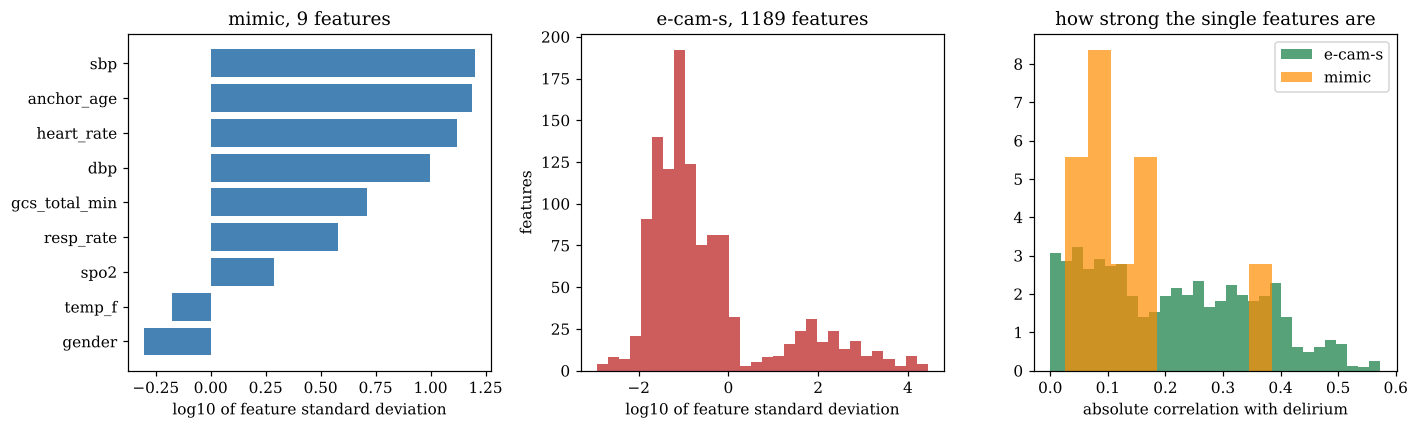

mimic std range: 0.5 to 15.85
ecams std range: 0.0012 to 27354.8
mimic top correlations: {'gcs_total_min': 0.38, 'spo2': 0.17, 'temp_f': 0.15}
ecams features over 0.3: 358 max: 0.57


ecams features with a partner over 0.95: 1058


In [4]:
# eda, how different the feature scales are and how strongly each feature relates to the outcome
fig, ax = plt.subplots(1, 3, figsize = (13, 4))
sm = Xm.std().sort_values()
ax[0].barh(sm.index, np.log10(sm.values), color = 'steelblue')
ax[0].set_xlabel('log10 of feature standard deviation')
ax[0].set_title('mimic, 9 features')
ax[1].hist(np.log10(Xe.std()), bins = 30, color = 'indianred')
ax[1].set_xlabel('log10 of feature standard deviation')
ax[1].set_ylabel('features')
ax[1].set_title('e-cam-s, 1189 features')
cm = Xe.corrwith(ye).abs()
cmm = Xm.fillna(Xm.median()).corrwith(ym).abs()
ax[2].hist(cm, bins = 30, color = 'seagreen', alpha = 0.8, density = True, label = 'e-cam-s')
ax[2].hist(cmm, bins = 9, color = 'darkorange', alpha = 0.7, density = True, label = 'mimic')
ax[2].set_xlabel('absolute correlation with delirium')
ax[2].set_title('how strong the single features are')
ax[2].legend()
plt.tight_layout()
plt.savefig('figs/w8_eda.png', dpi = 200)
plt.show()
print('mimic std range:', round(Xm.std().min(), 2), 'to', round(Xm.std().max(), 2))
print('ecams std range:', round(Xe.std().min(), 4), 'to', round(Xe.std().max(), 1))
print('mimic top correlations:', cmm.sort_values(ascending = False).head(3).round(2).to_dict())
print('ecams features over 0.3:', int((cm > 0.3).sum()), 'max:', round(cm.max(), 2))
cmat = Xe.corr().abs().values.copy()
np.fill_diagonal(cmat, 0)
print('ecams features with a partner over 0.95:', int((cmat.max(axis = 1) > 0.95).sum()))

The scales are the first thing to deal with. On MIMIC the standard deviations run from about 0.5 for the gender flag to almost 16 for systolic pressure, so systolic pressure, age and heart rate will dominate a raw distance. On ECAMS it's far worse, the standard deviations go from 0.0012 to over 27,000. The ECAMS features are also very redundant, 1058 of the 1189 have another feature correlated with them above 0.95, and 358 correlate with delirium at more than 0.3 (the largest is 0.57). On MIMIC the strongest single feature is gcs_total_min at 0.38 and the rest are weak, spo2 at 0.17 and temp_f at 0.15. So I expect scaling to matter a lot for KNN, and I expect ECAMS to do better than MIMIC because it has more rows and stronger single features.

In [5]:
# knn helper, imputation and scaling are inside the pipeline so every fold stays clean
def knn_pipe(k, metric = 'euclidean', scale = True, weights = 'uniform'):
    steps = [SimpleImputer(strategy = 'median')]
    if scale:
        steps.append(StandardScaler())
    algo = 'brute' if metric == 'cosine' else 'auto'
    steps.append(KNeighborsClassifier(n_neighbors = k, metric = metric, weights = weights, algorithm = algo))
    return make_pipeline(*steps)

def cv_auc(name, model, train = False):
    X, y = data[name]
    r = cross_validate(model, X, y, cv = cv_clf, scoring = 'roc_auc', return_train_score = train, n_jobs = 2)
    if train:
        return r['train_score'].mean(), r['test_score'].mean(), r['test_score'].std()
    return r['test_score'].mean(), r['test_score'].std()

ks = {'mimic': [1, 3, 5, 7, 11, 15, 21, 31, 45, 61], 'ecams': [1, 3, 5, 7, 11, 15, 21, 31, 45, 61, 91]}
metrics = ['euclidean', 'manhattan', 'chebyshev', 'cosine']
rows = []
for name in data:
    for m in metrics:
        for k in ks[name]:
            tr, va, sd = cv_auc(name, knn_pipe(k, m), train = True)
            rows.append({'data': name, 'metric': m, 'k': k, 'train auc': tr, 'cv auc': va, 'sd': sd})
sweep = pd.DataFrame(rows)
sweep.to_csv('figs/w8_knn_sweep.csv', index = False)
best = sweep.loc[sweep.groupby(['data', 'metric'])['cv auc'].idxmax()]
best.round(3)

,data,metric,k,train auc,cv auc,sd
68,ecams,chebyshev,21,0.817,0.750,0.065
80,ecams,cosine,31,0.897,0.884,0.038
48,ecams,euclidean,45,0.889,0.879,0.038
59,ecams,manhattan,45,0.892,0.883,0.037
23,mimic,chebyshev,7,0.827,0.694,0.083
37,mimic,cosine,31,0.795,0.759,0.073
5,mimic,euclidean,15,0.809,0.730,0.056
17,mimic,manhattan,31,0.799,0.767,0.092


With scaled features the metric matters on MIMIC and mostly doesn't on ECAMS. On MIMIC manhattan is best at a cv auc of 0.767 (k of 31), then cosine at 0.759, euclidean at 0.730 and chebyshev last at 0.694. On ECAMS cosine, manhattan and euclidean land within 0.005 of each other (0.884, 0.883 and 0.879) and chebyshev falls way behind at 0.750. Chebyshev only looks at the single biggest coordinate difference, which with 1189 features throws away almost everything. My guess on why manhattan likes the small MIMIC data is that squared differences let one odd vital sign pull a stay far from everything else, while absolute differences are gentler.

In [6]:
# unscaled against scaled, same grid with the metric fixed at euclidean
rows = []
for name in data:
    for sc in [False, True]:
        res = [(k, cv_auc(name, knn_pipe(k, 'euclidean', scale = sc))[0]) for k in ks[name]]
        kb, ab = max(res, key = lambda t: t[1])
        rows.append({'data': name, 'scaled': sc, 'best k': kb, 'cv auc': ab})
pd.DataFrame(rows).round(3)

,data,scaled,best k,cv auc
0,mimic,False,3,0.643
1,mimic,True,15,0.730
2,ecams,False,91,0.698
3,ecams,True,45,0.879


Scaling is the biggest single effect in the notebook. On MIMIC the best unscaled model gets a cv auc of 0.643 and the scaled one 0.730, and on ECAMS it's 0.698 unscaled against 0.879 scaled. Without scaling a handful of features with huge variances are the only ones that count in the distance, which matches what the EDA showed.

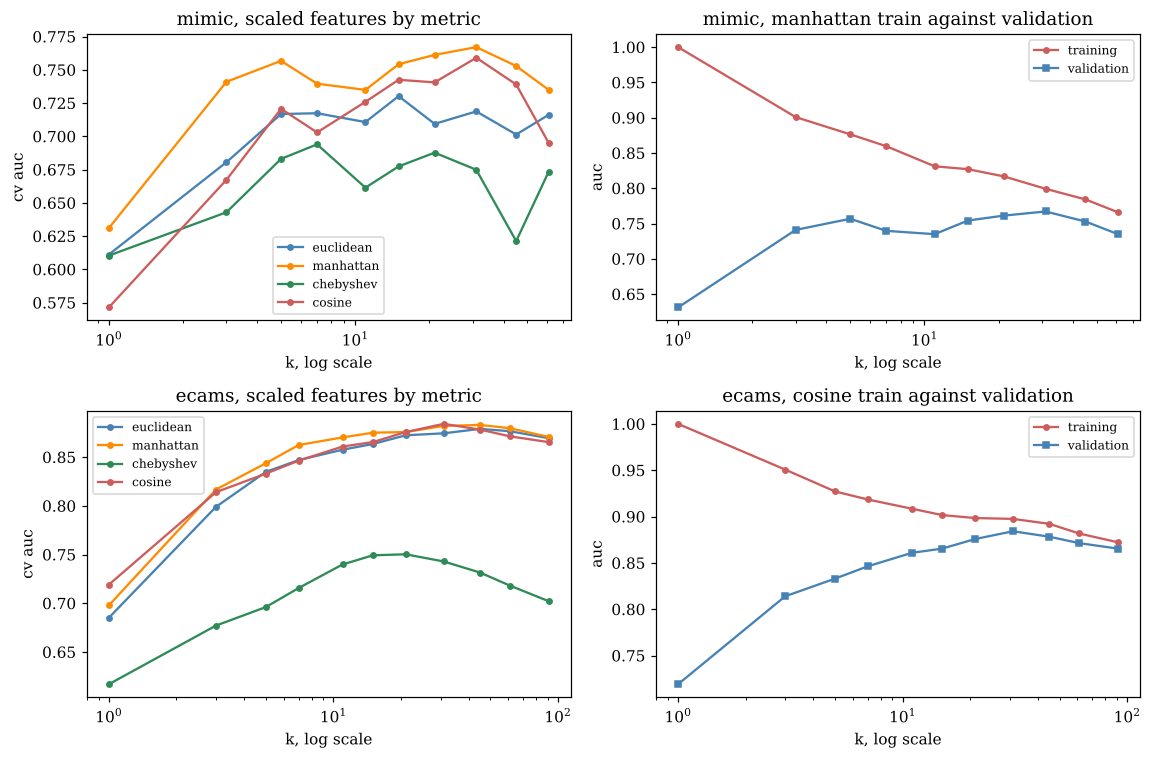

In [7]:
# figure, metric curves on the left and training against validation on the right
fig, ax = plt.subplots(2, 2, figsize = (10.5, 7))
cols = {'euclidean': 'steelblue', 'manhattan': 'darkorange', 'chebyshev': 'seagreen', 'cosine': 'indianred'}
for i, name in enumerate(data):
    s = sweep[sweep.data == name]
    for m in metrics:
        t = s[s.metric == m]
        ax[i, 0].plot(t['k'], t['cv auc'], 'o-', color = cols[m], label = m, markersize = 3.5)
    ax[i, 0].set_xscale('log')
    ax[i, 0].set_xlabel('k, log scale')
    ax[i, 0].set_ylabel('cv auc')
    ax[i, 0].set_title(name + ', scaled features by metric')
    ax[i, 0].legend(fontsize = 8)
    bm = best[best.data == name].sort_values('cv auc').iloc[-1]['metric']
    t = s[s.metric == bm]
    ax[i, 1].plot(t['k'], t['train auc'], 'o-', color = 'indianred', label = 'training', markersize = 3.5)
    ax[i, 1].plot(t['k'], t['cv auc'], 's-', color = 'steelblue', label = 'validation', markersize = 3.5)
    ax[i, 1].set_xscale('log')
    ax[i, 1].set_xlabel('k, log scale')
    ax[i, 1].set_ylabel('auc')
    ax[i, 1].set_title(name + ', ' + bm + ' train against validation')
    ax[i, 1].legend(fontsize = 8)
plt.tight_layout()
plt.savefig('figs/w8_knn.png', dpi = 200)
plt.show()

The right column is the overfitting picture. At k of 1 the training auc is exactly 1.0 because every point is its own nearest neighbor, while validation is only 0.63 on MIMIC (manhattan) and 0.72 on ECAMS (cosine). Training and validation come together as k grows. At k of 31 the gap is 0.03 on MIMIC (0.799 against 0.767) and 0.013 on ECAMS (0.897 against 0.884). The MIMIC validation curve is jumpy, it bounces between 0.735 and 0.767 from k of 11 to 45, because each training fold only has 112 stays, so I wouldn't read anything into the exact peak. The ECAMS curve is smooth and flattens out around k of 30 to 45.

In [8]:
# pca before knn on the e-cam-s features, the 1189 columns are mostly copies of each other
rows = []
for nc in [2, 5, 10, 20, 40, 80]:
    for k in [11, 21, 31]:
        m = make_pipeline(StandardScaler(), PCA(nc), KNeighborsClassifier(n_neighbors = k))
        rows.append({'components': nc, 'k': k, 'cv auc': cv_auc('ecams', m)[0]})
pca_knn = pd.DataFrame(rows).pivot(index = 'components', columns = 'k', values = 'cv auc')
pca_knn.round(3)

k,11,21,31
components,,,
2,0.811,0.833,0.843
5,0.829,0.847,0.859
10,0.853,0.871,0.873
20,0.855,0.870,0.873
40,0.858,0.870,0.873
80,0.857,0.870,0.877


Ten principal components already gets a cv auc of 0.873 at k of 31, and 80 components only gets 0.876, so the 1189 columns really are mostly copies of each other. Two components alone still reach 0.843. PCA didn't beat the full scaled data (about 0.88 at best) but it matches it with 10 columns instead of 1189.

In [9]:
# nested tuning, k metric and weights picked by an inner 5 fold search inside each outer fold
grid = {'kneighborsclassifier__n_neighbors': [3, 5, 9, 15, 21, 31, 45], 'kneighborsclassifier__metric': ['euclidean', 'manhattan', 'cosine'], 'kneighborsclassifier__weights': ['uniform', 'distance']}
rf_grid = {'max_depth': [3, 5, None], 'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.5]}
models = {
    'knn, k 5 default': knn_pipe(5),
    'knn, tuned inside folds': GridSearchCV(knn_pipe(5), grid, scoring = 'roc_auc', cv = 5),
    'logistic, cv regularized': make_pipeline(SimpleImputer(strategy = 'median'), StandardScaler(), LogisticRegressionCV(Cs = np.logspace(-3, 3, 20), cv = 5, scoring = 'roc_auc', max_iter = 5000)),
    'random forest, default': make_pipeline(SimpleImputer(strategy = 'median'), RandomForestClassifier(n_estimators = 300, random_state = 0))
}
scoring = ('roc_auc', 'recall', 'precision', 'f1', 'accuracy')
rows = []
for name in data:
    X, y = data[name]
    for mn, m in models.items():
        r = cross_validate(m, X, y, cv = cv_clf, scoring = scoring, n_jobs = 2)
        rows.append({'data': name, 'model': mn, 'auc': r['test_roc_auc'].mean(), 'auc sd': r['test_roc_auc'].std(), 'recall': r['test_recall'].mean(), 'precision': r['test_precision'].mean(), 'f1': r['test_f1'].mean(), 'accuracy': r['test_accuracy'].mean()})
        print(name, mn, round(rows[-1]['auc'], 3))
knn_tab = pd.DataFrame(rows)
knn_tab.to_csv('figs/w8_summary.csv', index = False)
knn_tab.round(3)

mimic knn, k 5 default 0.717


mimic knn, tuned inside folds 0.741


mimic logistic, cv regularized 0.75


mimic random forest, default 0.779


ecams knn, k 5 default 0.835


ecams knn, tuned inside folds 0.874


ecams logistic, cv regularized 0.876


ecams random forest, default 0.898


,data,model,auc,auc sd,recall,precision,f1,accuracy
0,mimic,"knn, k 5 default",0.717,0.088,0.563,0.577,0.557,0.721
1,mimic,"knn, tuned inside folds",0.741,0.085,0.178,0.586,0.248,0.698
2,mimic,"logistic, cv regularized",0.750,0.088,0.311,0.529,0.365,0.707
3,mimic,"random forest, default",0.779,0.105,0.519,0.653,0.565,0.745
4,ecams,"knn, k 5 default",0.835,0.033,0.828,0.848,0.836,0.780
5,ecams,"knn, tuned inside folds",0.874,0.038,0.867,0.851,0.857,0.805
6,ecams,"logistic, cv regularized",0.876,0.039,0.889,0.847,0.867,0.814
7,ecams,"random forest, default",0.898,0.024,0.882,0.858,0.869,0.819


Under nested tuning KNN is competitive on ECAMS and behind on MIMIC. On ECAMS the tuned KNN gets an auc of 0.874, the same as cv regularized logistic regression (0.876) and a bit below the default random forest (0.898). On MIMIC the order is forest 0.779, logistic 0.750, tuned KNN 0.741 and k of 5 KNN 0.717. Tuning k and the metric inside the folds bought about 0.02 on MIMIC and 0.04 on ECAMS over a default k of 5. The tuned MIMIC KNN has a recall of only 0.18, because it settled on a big k with distance weights, and with 32 percent positives a large neighborhood mostly votes negative at a cutoff of 0.5. Auc is fine with that but recall isn't, so for a screening tool the threshold would have to move.

In [10]:
# holdout check with a bootstrap interval on the test auc
rng = np.random.default_rng(0)
rows = []
for name in data:
    Xtr, Xte, ytr, yte = splits[name]
    for mn in ['knn, tuned inside folds', 'logistic, cv regularized', 'random forest, default']:
        m = models[mn].fit(Xtr, ytr)
        p = m.predict_proba(Xte)[:, 1]
        yt = yte.values
        boots = []
        for b in range(1000):
            idx = rng.integers(0, len(yt), len(yt))
            if yt[idx].min() != yt[idx].max():
                boots.append(roc_auc_score(yt[idx], p[idx]))
        rows.append({'data': name, 'model': mn, 'test rows': len(yt), 'positives': int(yt.sum()), 'test auc': roc_auc_score(yt, p), 'low': np.percentile(boots, 2.5), 'high': np.percentile(boots, 97.5)})
        if 'knn' in mn:
            print(name, m.best_params_ if hasattr(m, 'best_params_') else '')
pd.DataFrame(rows).round(3)

mimic {'kneighborsclassifier__metric': 'manhattan', 'kneighborsclassifier__n_neighbors': 31, 'kneighborsclassifier__weights': 'distance'}


ecams {'kneighborsclassifier__metric': 'manhattan', 'kneighborsclassifier__n_neighbors': 45, 'kneighborsclassifier__weights': 'uniform'}


,data,model,test rows,positives,test auc,low,high
0,mimic,"knn, tuned inside folds",28,9,0.836,0.667,0.967
1,mimic,"logistic, cv regularized",28,9,0.801,0.614,0.946
2,mimic,"random forest, default",28,9,0.854,0.678,0.994
3,ecams,"knn, tuned inside folds",75,51,0.868,0.784,0.940
4,ecams,"logistic, cv regularized",75,51,0.892,0.804,0.955
5,ecams,"random forest, default",75,51,0.873,0.781,0.943


On the holdout split the tuned KNN gets an auc of 0.836 on MIMIC and 0.868 on ECAMS. The intervals are wide though, 0.67 to 0.97 on MIMIC where the 28 test stays only include 9 positives, and 0.78 to 0.94 on ECAMS. The MIMIC holdout numbers (0.80 to 0.85 for all three models) are higher than their cv numbers (0.74 to 0.78), which I read as the small test set being friendly, not the models being better than cv said. The search picked manhattan on both datasets, with k of 31 and distance weights on MIMIC and k of 45 on ECAMS.

To sum up, KNN works about as well as logistic regression on ECAMS and a bit worse on MIMIC, scaling is not optional, and the metric only matters when the feature count is small or the metric ignores most of the features (chebyshev).